# 04. Model Training

**Group 24 - EC5203 Machine Learning - Fetal Well-being Classification (JNU-CTG)**

**Goal:** train the models on the training set and compare them on the **validation set**. The test set is not used here.

**Parts** (each part loads the data itself, so it can be run on its own)
1. Logistic Regression (1a, 1b unscaled; 1c scaled)
2. Random Forest
3. XGBoost
4. LightGBM
4b. K-Nearest Neighbours (unscaled vs scaled)

Some models have two versions written by different team members. Both are kept so nobody's work is lost;
the team can decide later which version to keep.

In [1]:
# Settings: imports, paths, column names and the random seed.
# These used to live in config/config.py. Each notebook now has its own copy,
# so the project no longer needs the src/ or config/ folders.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Find the project root: the first folder (going upwards) that contains data/raw.
# This works on every team member's computer - no personal C:/ or F:/ paths.
PROJECT_ROOT = Path.cwd()
for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / "data" / "raw").is_dir():
        PROJECT_ROOT = folder
        break

# Data files
RAW_DATA_FILE = PROJECT_ROOT / "data" / "raw" / "metadata.csv"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_TRAIN_FILE = PROCESSED_DATA_DIR / "train.csv"
PROCESSED_VAL_FILE = PROCESSED_DATA_DIR / "val.csv"
PROCESSED_TEST_FILE = PROCESSED_DATA_DIR / "test.csv"   # used ONCE, only in the final evaluation

# All saved tables go into ONE flat results folder (no separate figures/metrics folders)
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
METRICS_DIR = RESULTS_DIR
FIGURES_DIR = RESULTS_DIR
FEATURE_IMPORTANCE_DIR = RESULTS_DIR

# Column names
TARGET_COLUMN = "figo_label"        # 0 = normal, 1 = abnormal (positive class)
PATIENT_ID_COLUMN = "patient_id"    # used only to group the split, never a feature
RECORD_ID_COLUMN = "record_id"      # used only for traceability, never a feature

# Experiment settings
RANDOM_STATE = 42
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CORRELATION_THRESHOLD = 0.90
TOP_K_VALUES = [10, 20, 30, 50]

print("Project root:", PROJECT_ROOT)
print("Random seed: ", RANDOM_STATE)


Project root: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features
Random seed:  42


---
## Part 1a - Logistic Regression baseline (no preprocessing)

*Moved from `notebooks/baselines/04a_logistic_regression_baseline.ipynb` - author: not recorded in git - please add your name*

## 04. Logistic Regression Model Training — Baseline (no preprocessing)

This notebook trains a **Logistic Regression** classifier with **default settings** on all **103 signal features**, without any preprocessing, to get a first baseline score.

It uses exactly the same data and steps as `04d_lightgbm_baseline.ipynb`, so the two results can be compared.

Important difference from LightGBM:
- Logistic Regression is **sensitive to feature scale**. Features with large values (for example power or energy features) can dominate the model, and the solver may need more iterations to converge.
- No scaling is done here **on purpose**: this run shows how Logistic Regression performs *without* preprocessing.
- If a `ConvergenceWarning` appears, it is a real result of this experiment and is **not hidden**.

Rules followed:
- Train on `train.csv` only, score on `val.csv` only.
- `test.csv` is **not loaded** in this notebook.
- `record_id`, `patient_id` and `figo_label` are not used as input features.
- Positive class = abnormal (`figo_label = 1`). Threshold = 0.5 (default).

### Step 1: Setup and imports

In [2]:
import sys
import time
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, balanced_accuracy_score, confusion_matrix


### Step 2: Load the training and validation sets

The test set stays untouched until the final evaluation.

In [3]:
# Load train and validation sets only (test set stays untouched)
train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(PROCESSED_VAL_FILE)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (14540, 106)
Validation shape: (3115, 106)


In [4]:
# Settings for finding the 103 signal features
NUMBER_OF_FEATURES = 103
FEATURE_PREFIXES = ["F_", "U_", "FU_"]


def get_feature_columns(df):
    """Return a list with the names of the 103 signal feature columns."""
    feature_cols = []
    for col in df.columns:
        for prefix in FEATURE_PREFIXES:
            if col.startswith(prefix):
                feature_cols.append(col)
                break

    print("Number of feature columns found:", len(feature_cols))

    # Stop if we did not get exactly 103 features
    if len(feature_cols) != NUMBER_OF_FEATURES:
        raise ValueError(
            "Expected 103 features but found " + str(len(feature_cols)) + "."
        )

    return feature_cols

### Step 3: Separate features (X) and target (y)

In [5]:
# Get the 103 signal features (IDs and target are excluded)
feature_cols = get_feature_columns(train_df)

X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMN]

print("Train:", X_train.shape, " Validation:", X_val.shape)

Number of feature columns found: 103
Train: (14540, 103)  Validation: (3115, 103)


### Step 4: Create and train the Logistic Regression model

Default hyperparameters (solver `lbfgs`, `max_iter=100`); the random seed is fixed for consistency with the other notebooks.

In [6]:
# Create Logistic Regression with default settings (only the seed is fixed)
model = LogisticRegression(random_state=RANDOM_STATE)

# Train on the training set only
start_time = time.time()
model.fit(X_train, y_train)
train_seconds = time.time() - start_time

print("Training time (seconds):", round(train_seconds, 2))

# Number of iterations the solver used (if it equals 100, it stopped at the limit)
print("Solver iterations used:", model.n_iter_[0])

Training time (seconds): 0.43
Solver iterations used: 100


c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Step 5: Predict on the validation set

In [7]:
# Class predictions (threshold 0.5 by default)
val_pred = model.predict(X_val)

# Probability of abnormal (1), needed for ROC-AUC
val_prob = model.predict_proba(X_val)[:, 1]

### Step 6: Validation metrics

Positive class = abnormal (`figo_label = 1`).

In [8]:
print("Accuracy:         ", round(accuracy_score(y_val, val_pred), 4))
print("Precision:        ", round(precision_score(y_val, val_pred), 4))
print("Recall:           ", round(recall_score(y_val, val_pred), 4))
print("F1-score:         ", round(f1_score(y_val, val_pred), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_val, val_prob), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, val_pred))

Accuracy:          0.713
Precision:         0.742
Recall:            0.7154
F1-score:          0.7284
ROC-AUC:           0.7863
Balanced accuracy: 0.7128
Confusion matrix [[TN, FP], [FN, TP]]:
[[1022  417]
 [ 477 1199]]


### Step 7: Check for overfitting

If the training F1 is much higher than the validation F1, the model is overfitting.

In [9]:
# Training F1, compared with validation F1 from Step 6
train_pred = model.predict(X_train)
print("Training F1:  ", round(f1_score(y_train, train_pred), 4))
print("Validation F1:", round(f1_score(y_val, val_pred), 4))

Training F1:   0.729
Validation F1: 0.7284


---
## Part 1b - Logistic Regression on unscaled features

*Moved from `notebooks/07_logistic_regression_baseline.ipynb` - author: Anusikan*

## Logistic Regression training on unscaled features

Open the notebook in VS Code, select the project's `.venv` kernel, and run the four code cells in order with **Shift+Enter**. The model uses the existing 103 CTG features exactly as stored in the shared training CSV.

### 1. Set up
Import the libraries and locate the shared training CSV. Check the printed path before continuing.

In [10]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

relative_path = Path("data/processed/train.csv")
train_path = next(
    (folder / relative_path for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / relative_path).is_file()),
    None,
)
if train_path is None:
    raise FileNotFoundError("Open the repository folder in VS Code before running this notebook.")
print(f"Training data: {train_path}")

Training data: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\data\processed\train.csv


### 2. Load and check the training data
Select the 103 feature columns by prefix and use `figo_label` as the target. Verify that the values are numeric and finite and that both labels are present. These checks leave the feature values unchanged.

In [11]:
train = pd.read_csv(train_path)
features = [column for column in train if column.startswith(("F_", "U_", "FU_"))]
if len(features) != 103:
    raise ValueError(f"Expected 103 CTG predictors, found {len(features)}.")

X_train = train[features]
y_train = train["figo_label"]
if y_train.isna().any() or set(y_train) != {0, 1}:
    raise ValueError("Expected both FIGO labels, 0 (normal) and 1 (abnormal).")
if not all(pd.api.types.is_numeric_dtype(X_train[column]) for column in features):
    raise ValueError("All CTG predictors must be numeric.")
if not np.isfinite(X_train.to_numpy(dtype=float)).all():
    raise ValueError("The training features contain missing or infinite values.")

print(f"Training shape: {X_train.shape}")
print(y_train.value_counts().sort_index().to_string())

Training shape: (14540, 103)
figo_label
0    6719
1    7821


### 3. Fit Logistic Regression
Fit the classifier directly on the training features. The solver uses L-BFGS, `C=1.0`, tolerance `1e-4`, and seed 42. If the first fit warns, the cell retries with a higher iteration limit. Check the printed iteration count and convergence status.

In [12]:
model_settings = {"solver": "lbfgs", "C": 1.0, "tol": 1e-4, "random_state": 42}
for max_iter in (1000, 5000):
    model = LogisticRegression(max_iter=max_iter, **model_settings)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)

    convergence_warnings = [
        item for item in caught if issubclass(item.category, ConvergenceWarning)
    ]
    print(f"max_iter={max_iter}, iterations used={model.n_iter_[0]}")
    for item in caught:
        print(f"{item.category.__name__}: {item.message}")
    if not convergence_warnings:
        print("Training finished without a convergence warning.")
        break
else:
    print("The solver still warned at the final iteration limit.")

max_iter=1000, iterations used=143
Training finished without a convergence warning.


### 4. Evaluate on validation data
Predict labels for the shared validation recordings. Abnormal-class F1 is the primary comparison metric. Precision describes the correctness of abnormal predictions, sensitivity measures how many abnormal recordings are detected, and specificity measures how many normal recordings are identified correctly. Accuracy summarizes all predictions. The confusion matrix shows actual classes in rows and predicted classes in columns.

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

if "model" not in globals() or "convergence_warnings" not in globals():
    raise RuntimeError("Run the first three code cells in order to fit Logistic Regression.")
if convergence_warnings:
    raise RuntimeError("Resolve the training convergence warning before evaluating.")

val = pd.read_csv(train_path.with_name("val.csv"))
y_val = val["figo_label"]
predictions = model.predict(val[features])
metrics = pd.Series({
    "Abnormal F1 (primary)": f1_score(y_val, predictions, pos_label=1, zero_division=0),
    "Accuracy": accuracy_score(y_val, predictions),
    "Abnormal precision": precision_score(y_val, predictions, pos_label=1, zero_division=0),
    "Sensitivity (abnormal recall)": recall_score(y_val, predictions, pos_label=1, zero_division=0),
    "Specificity (normal recall)": recall_score(y_val, predictions, pos_label=0, zero_division=0),
}, name="Validation score")
print(metrics.to_string(float_format="{:.4f}".format))
print("\nConfusion matrix")
print(pd.DataFrame(
    confusion_matrix(y_val, predictions, labels=[0, 1]),
    index=["Actual normal", "Actual abnormal"],
    columns=["Predicted normal", "Predicted abnormal"],
))

Abnormal F1 (primary)           0.7711
Accuracy                        0.7618
Abnormal precision              0.7982
Sensitivity (abnormal recall)   0.7458
Specificity (normal recall)     0.7804

Confusion matrix
                 Predicted normal  Predicted abnormal
Actual normal                1123                 316
Actual abnormal               426                1250


---
## Part 1c - Logistic Regression WITH scaling

*New section - same model as Parts 1a/1b, but the features are scaled first.*

`StandardScaler` is inside a `Pipeline`, so it is fitted on the **training set only**.
Compare this validation F1 with Parts 1a / 1b (unscaled) - see also `02_preprocessing`, Part C.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

# Load the shared train and validation sets (the test set is NOT used here)
part_train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
part_val_df = pd.read_csv(PROCESSED_VAL_FILE)

part_features = []
for col in part_train_df.columns:
    if col.startswith("F_") or col.startswith("U_") or col.startswith("FU_"):
        part_features.append(col)
if len(part_features) != 103:
    raise ValueError("Expected 103 CTG features, found " + str(len(part_features)))

X_train_part = part_train_df[part_features]
y_train_part = part_train_df[TARGET_COLUMN].astype(int)
X_val_part = part_val_df[part_features]
y_val_part = part_val_df[TARGET_COLUMN].astype(int)
print("Train:", X_train_part.shape, " Validation:", X_val_part.shape)

Train: (14540, 103)  Validation: (3115, 103)


Logistic Regression (scaled) - validation metrics:
   accuracy = 0.9775
   precision = 0.9826
   recall = 0.9755
   f1 = 0.979
   roc_auc = 0.9981
   balanced_accuracy = 0.9777


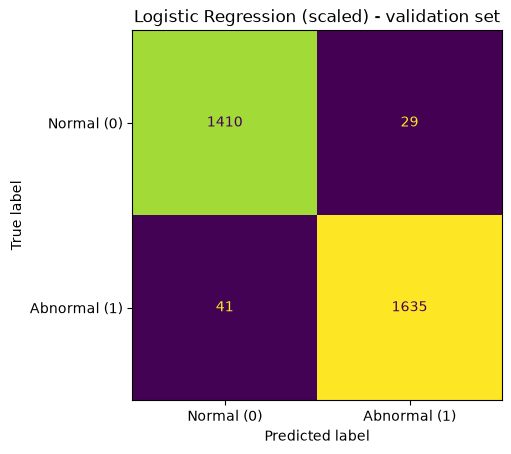

Saved: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\logistic_regression_scaled_validation.csv


In [15]:
def validation_metrics(model, X_val, y_val):
    """Return the validation metrics of a trained model as a dictionary (positive class = 1, abnormal)."""
    y_pred = model.predict(X_val)
    y_score = model.predict_proba(X_val)[:, 1]
    metrics = {}
    metrics["accuracy"] = accuracy_score(y_val, y_pred)
    metrics["precision"] = precision_score(y_val, y_pred)
    metrics["recall"] = recall_score(y_val, y_pred)
    metrics["f1"] = f1_score(y_val, y_pred)
    metrics["roc_auc"] = roc_auc_score(y_val, y_score)
    metrics["balanced_accuracy"] = balanced_accuracy_score(y_val, y_pred)
    return metrics, y_pred


# Scale -> Logistic Regression (default settings, enough iterations to finish training)
lr_scaled_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
lr_scaled_pipeline.fit(X_train_part, y_train_part)

lr_scaled_metrics, lr_scaled_pred = validation_metrics(lr_scaled_pipeline, X_val_part, y_val_part)
print("Logistic Regression (scaled) - validation metrics:")
for metric_name in lr_scaled_metrics:
    print("  ", metric_name, "=", round(lr_scaled_metrics[metric_name], 4))

cm_display = ConfusionMatrixDisplay(confusion_matrix(y_val_part, lr_scaled_pred), display_labels=["Normal (0)", "Abnormal (1)"])
cm_display.plot(colorbar=False, values_format="d")
plt.title("Logistic Regression (scaled) - validation set")
plt.show()

lr_scaled_table = pd.DataFrame([lr_scaled_metrics])
lr_scaled_table.insert(0, "model", "Logistic Regression (scaled)")
lr_scaled_table.to_csv(RESULTS_DIR / "logistic_regression_scaled_validation.csv", index=False)
print("Saved:", RESULTS_DIR / "logistic_regression_scaled_validation.csv")

---
## Part 2a - Random Forest baseline (no preprocessing)

*Moved from `notebooks/baselines/04b_random_forest_baseline.ipynb` - author: not recorded in git - please add your name*

## 04. Random Forest Model Training — Baseline (no preprocessing)

This notebook trains a **Random Forest** classifier with **default settings** on all **103 signal features**, without any preprocessing, to get a first baseline score.

It uses exactly the same data and steps as `04d_lightgbm_baseline.ipynb` and `04a_logistic_regression_baseline.ipynb`, so the results can be compared.

Why no preprocessing is acceptable here:
- **Scaling** is not needed: Random Forest is made of decision trees, which split on value thresholds, so feature scale does not matter.
- **Imputation** is not needed: the 103 features have no missing values.
- **Feature selection** is not done: this is the *full feature set* baseline.

Rules followed:
- Train on `train.csv` only, score on `val.csv` only.
- `test.csv` is **not loaded** in this notebook.
- `record_id`, `patient_id` and `figo_label` are not used as input features.
- Positive class = abnormal (`figo_label = 1`). Threshold = 0.5 (default).

### Step 1: Setup and imports

In [16]:
import sys
import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, balanced_accuracy_score, confusion_matrix


### Step 2: Load the training and validation sets

The test set stays untouched until the final evaluation.

In [17]:
# Load train and validation sets only (test set stays untouched)
train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(PROCESSED_VAL_FILE)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (14540, 106)
Validation shape: (3115, 106)


### Step 3: Separate features (X) and target (y)

In [18]:
# Get the 103 signal features (IDs and target are excluded)
feature_cols = get_feature_columns(train_df)

X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMN]

print("Train:", X_train.shape, " Validation:", X_val.shape)

Number of feature columns found: 103
Train: (14540, 103)  Validation: (3115, 103)


### Step 4: Create and train the Random Forest model

Default hyperparameters (100 trees, no depth limit); only the random seed is fixed for reproducibility.

In [19]:
# Create Random Forest with default settings (only the seed is fixed)
model = RandomForestClassifier(random_state=RANDOM_STATE)

# Train on the training set only
start_time = time.time()
model.fit(X_train, y_train)
train_seconds = time.time() - start_time

print("Training time (seconds):", round(train_seconds, 2))
print("Number of trees:", len(model.estimators_))

Training time (seconds): 7.57
Number of trees: 100


### Step 5: Predict on the validation set

In [20]:
# Class predictions (threshold 0.5 by default)
val_pred = model.predict(X_val)

# Probability of abnormal (1), needed for ROC-AUC
val_prob = model.predict_proba(X_val)[:, 1]

### Step 6: Validation metrics

Positive class = abnormal (`figo_label = 1`).

In [21]:
print("Accuracy:         ", round(accuracy_score(y_val, val_pred), 4))
print("Precision:        ", round(precision_score(y_val, val_pred), 4))
print("Recall:           ", round(recall_score(y_val, val_pred), 4))
print("F1-score:         ", round(f1_score(y_val, val_pred), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_val, val_prob), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, val_pred))

Accuracy:          0.886
Precision:         0.886
Recall:            0.9045
F1-score:          0.8952
ROC-AUC:           0.9616
Balanced accuracy: 0.8845
Confusion matrix [[TN, FP], [FN, TP]]:
[[1244  195]
 [ 160 1516]]


### Step 7: Check for overfitting

If the training F1 is much higher than the validation F1, the model is overfitting.
Default Random Forest trees grow with no depth limit, so a training F1 close to 1.0 is expected.

In [22]:
# Training F1, compared with validation F1 from Step 6
train_pred = model.predict(X_train)
print("Training F1:  ", round(f1_score(y_train, train_pred), 4))
print("Validation F1:", round(f1_score(y_val, val_pred), 4))

Training F1:   1.0
Validation F1: 0.8952


### Step 8: Top 15 most important features

Random Forest gives each feature an importance score (how much it helped the trees separate normal from abnormal).
This is only a first look, learned from the training set. It is **not** the feature selection of notebook 03.

In [23]:
# Put the feature names and their importance scores into a table
importance_table = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_,
})

# Sort from most to least important
importance_table = importance_table.sort_values("importance", ascending=False)

print(importance_table.head(15).to_string(index=False))

     feature  importance
 FU_RE_WCTTF    0.051838
       F_D_N    0.049501
  FU_V_WCTTF    0.047108
        F_SD    0.044858
      F_VD_N    0.038209
 FU_SE_WCTTF    0.030250
  F_LPF_ST11    0.027344
  FU_M_WCTTF    0.027087
   U_RE_STTF    0.023661
    U_V_STTF    0.021857
FU_LPF_XWT11    0.020028
  F_LPF_ST10    0.019751
FU_LPF_XWT10    0.019323
FU_LPF_WCT11    0.018782
FU_LPF_WCT10    0.018102


---
## Part 2b - Random Forest baseline with saved results

*Moved from `notebooks/04_random_forest_baseline.ipynb` - author: Mohamad Azeem*

## Random Forest baseline — all 103 CTG features

This notebook trains a reproducible Random Forest baseline for fetal well-being classification. It uses `train.csv` for fitting and `val.csv` for baseline evaluation. It deliberately does **not** load or inspect `test.csv`.

Baseline rules:
- Use all 103 columns beginning with `F_`, `U_`, or `FU_`.
- Never use `record_id` or `patient_id` as predictors.
- Fit `StandardScaler` on training data only and reuse it for validation data.
- No outlier handling and no feature selection.
- Use random seed 42.
- Select models primarily by abnormal-class F1 (`figo_label = 1`).

> Random Forest is based on decision-tree thresholds and does not normally need scaling. Scaling is included here as a leakage-safe pipeline step because it is part of the shared preprocessing workflow.

### Cell 1 — Imports and project paths

This cell imports the libraries and locates the project whether the notebook is launched from the project root or from `notebooks/`.

In [24]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_STATE)

Project root: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features
Random seed: 42


### Cell 2 — Load training and validation data

Only the training and validation files are loaded. The shared CSV files are read without modifying them.

In [25]:
train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(PROCESSED_VAL_FILE)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Training patients:", train_df[PATIENT_ID_COLUMN].nunique())
print("Validation patients:", val_df[PATIENT_ID_COLUMN].nunique())

Training shape: (14540, 106)
Validation shape: (3115, 106)
Training patients: 8742
Validation patients: 1904


### Cell 3 — Select and validate the 103 predictors

Feature names must begin with `F_`, `U_`, or `FU_`. Assertions stop the notebook if the datasets do not match the agreed structure, contain missing/non-finite values, or accidentally include identifiers.

In [26]:
FEATURE_PREFIXES = ("F_", "U_", "FU_")
feature_cols = [column for column in train_df.columns if column.startswith(FEATURE_PREFIXES)]
val_feature_cols = [column for column in val_df.columns if column.startswith(FEATURE_PREFIXES)]

assert len(feature_cols) == 103, f"Expected 103 features, found {len(feature_cols)}"
assert feature_cols == val_feature_cols, "Training and validation feature columns differ"
assert RECORD_ID_COLUMN not in feature_cols
assert PATIENT_ID_COLUMN not in feature_cols
assert TARGET_COLUMN not in feature_cols
assert set(train_df[TARGET_COLUMN].unique()) == {0, 1}
assert set(val_df[TARGET_COLUMN].unique()) == {0, 1}
assert np.isfinite(train_df[feature_cols].to_numpy()).all(), "Training features contain NaN or infinity"
assert np.isfinite(val_df[feature_cols].to_numpy()).all(), "Validation features contain NaN or infinity"

print("Validated feature count:", len(feature_cols))
print("First five features:", feature_cols[:5])
print("Last five features:", feature_cols[-5:])

Validated feature count: 103
First five features: ['F_BL', 'F_A_N', 'F_D_N', 'F_ED_N', 'F_VD_N']
Last five features: ['FU_M_XWTTF', 'FU_V_XWTTF', 'FU_S_XWTTF', 'FU_K_XWTTF', 'FU_C_XWTTF']


### Cell 4 — Build `X` predictors and `y` targets

`X` contains only the 103 CTG features. `y` contains `figo_label`. Patient and record identifiers remain outside the model.

In [27]:
X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMN]
X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMN]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Validation class counts:", y_val.value_counts().sort_index().to_dict())

X_train: (14540, 103) y_train: (14540,)
X_val: (3115, 103) y_val: (3115,)
Training class counts: {0: 6719, 1: 7821}
Validation class counts: {0: 1439, 1: 1676}


### Cell 5 — Record settings and create the pipeline

The pipeline prevents leakage: `StandardScaler.fit` sees only `X_train`, and the fitted scaler is reused automatically when predicting validation data. Random Forest settings are written explicitly for reproducibility.

In [28]:
model_settings = {
    "n_estimators": 100,
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "bootstrap": True,
    "class_weight": None,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("random_forest", RandomForestClassifier(**model_settings)),
])

print("Preprocessing: StandardScaler fitted on training data only")
print("Random Forest settings:")
display(pd.Series(model_settings, name="value").to_frame())

Preprocessing: StandardScaler fitted on training data only
Random Forest settings:


,value
n_estimators,100
criterion,gini
max_depth,None
min_samples_split,2
min_samples_leaf,1
max_features,sqrt
bootstrap,True
class_weight,None
random_state,42
n_jobs,-1


### Cell 6 — Train the baseline

Calling `fit` first learns scaling statistics from training data and then fits the Random Forest on the scaled training features.

In [29]:
baseline_pipeline.fit(X_train, y_train)
print("Baseline training complete.")

Baseline training complete.


### Cell 7 — Predict and calculate validation metrics

Precision, recall, and F1 use class `1` (abnormal) as the positive class. Abnormal-class F1 is the main comparison metric.

In [30]:
val_predictions = baseline_pipeline.predict(X_val)

validation_metrics = {
    "accuracy": float(accuracy_score(y_val, val_predictions)),
    "abnormal_precision": float(precision_score(y_val, val_predictions, pos_label=1)),
    "abnormal_recall": float(recall_score(y_val, val_predictions, pos_label=1)),
    "abnormal_f1": float(f1_score(y_val, val_predictions, pos_label=1)),
}

display(pd.Series(validation_metrics, name="validation_score").to_frame())

,validation_score
accuracy,0.886035
abnormal_precision,0.886483
abnormal_recall,0.903938
abnormal_f1,0.895126


### Cell 8 — Confusion matrix and classification report

The confusion matrix layout is `[[TN, FP], [FN, TP]]`. The classification report shows class-specific and aggregate results.

In [31]:
confusion = confusion_matrix(y_val, val_predictions, labels=[0, 1])
confusion_df = pd.DataFrame(
    confusion,
    index=["Actual normal (0)", "Actual abnormal (1)"],
    columns=["Predicted normal (0)", "Predicted abnormal (1)"],
)
display(confusion_df)

report_text = classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["normal (0)", "abnormal (1)"],
    digits=4,
)
print(report_text)

,Predicted normal (0),Predicted abnormal (1)
Actual normal (0),1245,194
Actual abnormal (1),161,1515


              precision    recall  f1-score   support

  normal (0)     0.8855    0.8652    0.8752      1439
abnormal (1)     0.8865    0.9039    0.8951      1676

    accuracy                         0.8860      3115
   macro avg     0.8860    0.8846    0.8852      3115
weighted avg     0.8860    0.8860    0.8859      3115



### Cell 9 — Save the immutable baseline record

This saves the data description, preprocessing choice, model settings, metrics, confusion matrix, full classification report, and row-level validation predictions. Future experiments should compare against these files using the same validation set.

In [32]:
metrics_dir = METRICS_DIR
metrics_dir.mkdir(parents=True, exist_ok=True)

report_dict = classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["normal (0)", "abnormal (1)"],
    output_dict=True,
)

baseline_record = {
    "experiment": "random_forest_baseline_all_103_features",
    "random_seed": RANDOM_STATE,
    "training_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "feature_count": len(feature_cols),
    "features": feature_cols,
    "target": TARGET_COLUMN,
    "positive_class": 1,
    "preprocessing": {
        "scaler": "StandardScaler",
        "scaler_fit_data": "training only",
        "outlier_handling": None,
        "feature_selection": None,
    },
    "model": "RandomForestClassifier",
    "model_settings": model_settings,
    "validation_metrics": validation_metrics,
    "confusion_matrix_labels_0_1": confusion.tolist(),
    "classification_report": report_dict,
}

metrics_path = metrics_dir / "random_forest_baseline_validation.json"
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(baseline_record, file, indent=2)

predictions_path = metrics_dir / "random_forest_baseline_validation_predictions.csv"
validation_predictions_df = val_df[[RECORD_ID_COLUMN, PATIENT_ID_COLUMN, TARGET_COLUMN]].copy()
validation_predictions_df["predicted_figo_label"] = val_predictions
validation_predictions_df.to_csv(predictions_path, index=False)

print("Saved metrics:", metrics_path)
print("Saved validation predictions:", predictions_path)

Saved metrics: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\random_forest_baseline_validation.json
Saved validation predictions: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\random_forest_baseline_validation_predictions.csv


### Interpretation and next step

This is the fixed baseline. Do not conclude that outliers caused a low score merely from this result. Any later outlier rule, feature selection method, or hyperparameter search must learn its rules from training data only and be compared on this exact validation split. Keep `test.csv` untouched until the team selects the final model.

In [33]:
# Random Forest without feature scaling
rf_without_scaling = RandomForestClassifier(**model_settings)

# Train directly with the original 103 training features
rf_without_scaling.fit(X_train, y_train)

# Predict using the original validation features
unscaled_val_predictions = rf_without_scaling.predict(X_val)

print("Random Forest without scaling completed.")

Random Forest without scaling completed.


In [34]:
# Calculate unscaled Random Forest metrics
unscaled_metrics = {
    "accuracy": accuracy_score(y_val, unscaled_val_predictions),
    "abnormal_precision": precision_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
    "abnormal_recall": recall_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
    "abnormal_f1": f1_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
}

comparison_df = pd.DataFrame({
    "Scaled Random Forest (%)": {
        metric: value * 100
        for metric, value in validation_metrics.items()
    },
    "Unscaled Random Forest (%)": {
        metric: value * 100
        for metric, value in unscaled_metrics.items()
    },
})

display(comparison_df.round(2))

,Scaled Random Forest (%),Unscaled Random Forest (%)
accuracy,88.60,88.60
abnormal_precision,88.65,88.60
abnormal_recall,90.39,90.45
abnormal_f1,89.51,89.52


In [35]:
comparison_path = (
    METRICS_DIR
    / "random_forest_scaling_comparison.csv"
)

comparison_df.to_csv(comparison_path)

print("Saved scaling comparison:", comparison_path)

Saved scaling comparison: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\random_forest_scaling_comparison.csv


In [36]:
# Calculate feature importance from the unscaled Random Forest
feature_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_without_scaling.feature_importances_,
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

# Convert importance to percentage
feature_importance_df["importance_percentage"] = (
    feature_importance_df["importance"] * 100
)

display(feature_importance_df.head(20))

,feature,importance,importance_percentage
0,FU_RE_WCTTF,0.051838,5.183797
1,F_D_N,0.049501,4.950121
2,FU_V_WCTTF,0.047108,4.710805
3,F_SD,0.044858,4.485847
4,F_VD_N,0.038209,3.820880
5,FU_SE_WCTTF,0.030250,3.024991
6,F_LPF_ST11,0.027344,2.734393
7,FU_M_WCTTF,0.027087,2.708651
8,U_RE_STTF,0.023661,2.366073
9,U_V_STTF,0.021857,2.185706


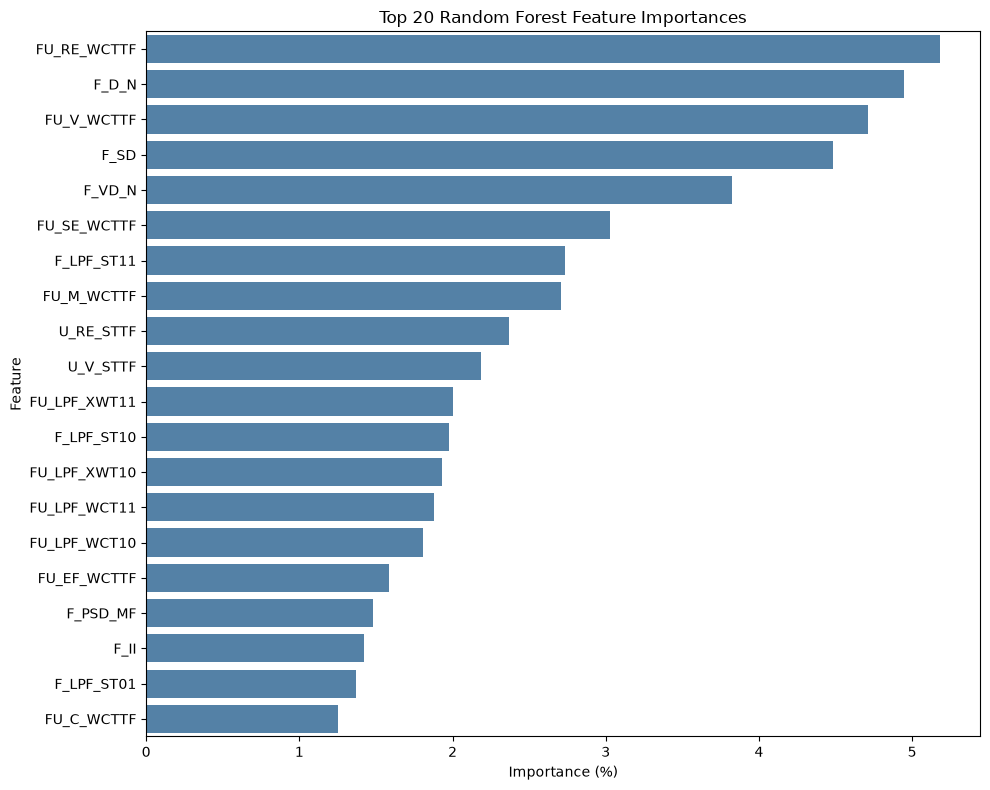

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20_features = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_20_features,
    x="importance_percentage",
    y="feature",
    color="steelblue"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [38]:
FEATURE_IMPORTANCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

feature_importance_path = (
    FEATURE_IMPORTANCE_DIR
    / "random_forest_baseline_feature_importance.csv"
)

feature_importance_df.to_csv(
    feature_importance_path,
    index=False
)

print(
    "Saved feature importance:",
    feature_importance_path
)

Saved feature importance: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\random_forest_baseline_feature_importance.csv


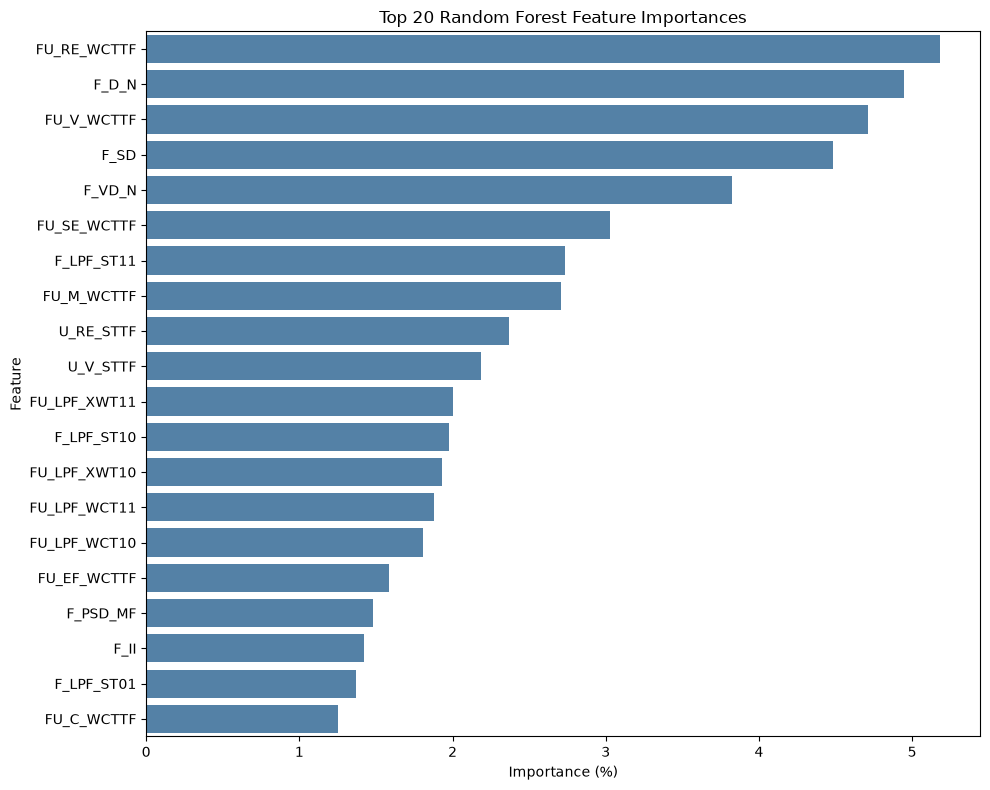

Saved feature-importance figure: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\random_forest_top_20_feature_importance.png


In [39]:
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    FIGURES_DIR
    / "random_forest_top_20_feature_importance.png"
)

top_20_features = feature_importance_df.head(20)

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    data=top_20_features,
    x="importance_percentage",
    y="feature",
    color="steelblue",
    ax=ax
)

ax.set_title("Top 20 Random Forest Feature Importances")
ax.set_xlabel("Importance (%)")
ax.set_ylabel("Feature")

fig.tight_layout()
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved feature-importance figure:", figure_path)

---
## Part 3a - XGBoost baseline (no preprocessing)

*Moved from `notebooks/baselines/04c_xgboost_baseline.ipynb` - author: not recorded in git - please add your name*

## 04. XGBoost Model Training — Baseline (no preprocessing)

This notebook trains an **XGBoost** classifier with **default settings** on all **103 signal features**, without any preprocessing, to get a first baseline score.

It uses exactly the same data and steps as `04d_lightgbm_baseline.ipynb`, `04a_logistic_regression_baseline.ipynb` and `04b_random_forest_baseline.ipynb`, so the results can be compared.

Why no preprocessing is acceptable here:
- **Scaling** is not needed: XGBoost is made of decision trees, which split on value thresholds, so feature scale does not matter.
- **Imputation** is not needed: the 103 features have no missing values.
- **Feature selection** is not done: this is the *full feature set* baseline.

Rules followed:
- Train on `train.csv` only, score on `val.csv` only.
- `test.csv` is **not loaded** in this notebook.
- `record_id`, `patient_id` and `figo_label` are not used as input features.
- Positive class = abnormal (`figo_label = 1`). Threshold = 0.5 (default).

### Step 1: Setup and imports

In [42]:
import sys
import time
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, balanced_accuracy_score, confusion_matrix


### Step 2: Load the training and validation sets

The test set stays untouched until the final evaluation.

In [43]:
# Load train and validation sets only (test set stays untouched)
train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(PROCESSED_VAL_FILE)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (14540, 106)
Validation shape: (3115, 106)


### Step 3: Separate features (X) and target (y)

In [44]:
# Get the 103 signal features (IDs and target are excluded)
feature_cols = get_feature_columns(train_df)

X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMN]

print("Train:", X_train.shape, " Validation:", X_val.shape)

Number of feature columns found: 103
Train: (14540, 103)  Validation: (3115, 103)


### Step 4: Create and train the XGBoost model

Default hyperparameters; only the random seed is fixed for reproducibility.

In [45]:
# Create XGBoost with default settings (only the seed is fixed)
model = XGBClassifier(random_state=RANDOM_STATE)

# Train on the training set only
start_time = time.time()
model.fit(X_train, y_train)
train_seconds = time.time() - start_time

print("Training time (seconds):", round(train_seconds, 2))

# Show the main default settings that were used
params = model.get_params()
print("n_estimators: ", params["n_estimators"])
print("max_depth:    ", params["max_depth"])
print("learning_rate:", params["learning_rate"])
print("(None means XGBoost uses its own internal default)")

Training time (seconds): 2.29
n_estimators:  None
max_depth:     None
learning_rate: None
(None means XGBoost uses its own internal default)


### Step 5: Predict on the validation set

In [46]:
# Class predictions (threshold 0.5 by default)
val_pred = model.predict(X_val)

# Probability of abnormal (1), needed for ROC-AUC
val_prob = model.predict_proba(X_val)[:, 1]

### Step 6: Validation metrics

Positive class = abnormal (`figo_label = 1`).

In [47]:
print("Accuracy:         ", round(accuracy_score(y_val, val_pred), 4))
print("Precision:        ", round(precision_score(y_val, val_pred), 4))
print("Recall:           ", round(recall_score(y_val, val_pred), 4))
print("F1-score:         ", round(f1_score(y_val, val_pred), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_val, val_prob), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, val_pred))

Accuracy:          0.94
Precision:         0.9429
Recall:            0.9457
F1-score:          0.9443
ROC-AUC:           0.9871
Balanced accuracy: 0.9395
Confusion matrix [[TN, FP], [FN, TP]]:
[[1343   96]
 [  91 1585]]


### Step 7: Check for overfitting

If the training F1 is much higher than the validation F1, the model is overfitting.

In [48]:
# Training F1, compared with validation F1 from Step 6
train_pred = model.predict(X_train)
print("Training F1:  ", round(f1_score(y_train, train_pred), 4))
print("Validation F1:", round(f1_score(y_val, val_pred), 4))

Training F1:   1.0
Validation F1: 0.9443


### Step 8: Top 15 most important features

XGBoost gives each feature an importance score (how much it helped the trees separate normal from abnormal).
This is only a first look, learned from the training set. It is **not** the feature selection of notebook 03.

In [49]:
# Put the feature names and their importance scores into a table
importance_table = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_,
})

# Sort from most to least important
importance_table = importance_table.sort_values("importance", ascending=False)

print(importance_table.head(15).to_string(index=False))

     feature  importance
  FU_V_WCTTF    0.172206
       F_D_N    0.054590
 FU_RE_WCTTF    0.047574
  F_LPF_ST11    0.039168
    U_V_STTF    0.028766
        F_SD    0.025914
    F_PSD_MF    0.022199
   F_K_CWTTF    0.020721
   F_M_CWTTF    0.020353
  F_RE_CWTTF    0.020022
FU_LPF_WCT11    0.017803
   F_S_CWTTF    0.016821
   F_V_CWTTF    0.015731
        U_MN    0.014368
      F_LD_N    0.014084


---
## Part 3b - XGBoost baseline

*Moved from `notebooks/07_xgboost_baseline.ipynb` - author: justinharshan7*

In [50]:
import pandas as pd
import numpy as np

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [51]:
from pathlib import Path

# Locate the project inside your Machine Learning folder.
ROOT = PROJECT_ROOT  # was a hard-coded personal path; now found automatically

train_df = pd.read_csv(ROOT / "data/processed/train.csv")
val_df = pd.read_csv(ROOT / "data/processed/val.csv")

# Select only the signal features, excluding IDs and the answer.
feature_cols = [
    col for col in train_df.columns
    if col.startswith(("F_", "U_", "FU_"))
]

X_train = train_df[feature_cols]
y_train = train_df["figo_label"]

X_val = val_df[feature_cols]
y_val = val_df["figo_label"]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Target labels:", sorted(y_train.unique()))

Training data: (14540, 103)
Validation data: (3115, 103)
Target labels: [np.int64(0), np.int64(1)]


In [52]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

model.fit(X_train, y_train)

print("XGBoost training complete!")

XGBoost training complete!


In [53]:
# Predict using the validation features.
y_pred = model.predict(X_val)

# Compare predictions with the known answers.
print("XGBoost baseline — validation results\n")

print(f"Accuracy:  {accuracy_score(y_val, y_pred):.2%}")
print(f"Precision: {precision_score(y_val, y_pred, zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_val, y_pred, zero_division=0):.2%}")
print(f"F1 score:  {f1_score(y_val, y_pred, zero_division=0):.2%}")

print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Abnormal"],
    zero_division=0,
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y_val, y_pred, labels=[0, 1]),
    index=["Actual normal", "Actual abnormal"],
    columns=["Predicted normal", "Predicted abnormal"],
))

XGBoost baseline — validation results

Accuracy:  93.10%
Precision: 93.25%
Recall:    93.97%
F1 score:  93.61%

Classification report:
              precision    recall  f1-score   support

      Normal       0.93      0.92      0.92      1439
    Abnormal       0.93      0.94      0.94      1676

    accuracy                           0.93      3115
   macro avg       0.93      0.93      0.93      3115
weighted avg       0.93      0.93      0.93      3115

Confusion matrix:
                 Predicted normal  Predicted abnormal
Actual normal                1325                 114
Actual abnormal               101                1575


---
## Part 4 - LightGBM baseline (no preprocessing)

*Moved from `notebooks/baselines/04d_lightgbm_baseline.ipynb` - author: not recorded in git - please add your name*

## 04. LightGBM Model Training — Baseline (no preprocessing)

This notebook trains a **LightGBM** classifier with **default settings** on all **103 signal features**, without any preprocessing, to get a first baseline score.

Why no preprocessing is acceptable here:
- **Scaling** is not needed: tree models split on value thresholds, so feature scale does not matter.
- **Imputation** is not needed: the processed data has no missing values (see `data/processed/README.md`).
- **Feature selection** is not done: this is the *full feature set* baseline.

Rules followed:
- Train on `train.csv` only, score on `val.csv` only.
- `test.csv` is **not loaded** in this notebook.
- `record_id`, `patient_id` and `figo_label` are not used as input features.
- Positive class = abnormal (`figo_label = 1`). Threshold = 0.5 (default).

### Step 1: Setup and imports

In [54]:
import sys
import time
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, balanced_accuracy_score, confusion_matrix


### Step 2: Load the training and validation sets

The test set stays untouched until the final evaluation.

In [55]:
# Load train and validation sets only (test set stays untouched)
train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(PROCESSED_VAL_FILE)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (14540, 106)
Validation shape: (3115, 106)


### Step 3: Separate features (X) and target (y)

In [56]:
# Get the 103 signal features (IDs and target are excluded)
feature_cols = get_feature_columns(train_df)

X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMN]

print("Train:", X_train.shape, " Validation:", X_val.shape)

Number of feature columns found: 103
Train: (14540, 103)  Validation: (3115, 103)


### Step 4: Create and train the LightGBM model

Default hyperparameters; only the random seed is fixed for reproducibility.

In [57]:
# Create LightGBM with default settings (only the seed is fixed)
model = LGBMClassifier(random_state=RANDOM_STATE)

# Train on the training set only
start_time = time.time()
model.fit(X_train, y_train)
train_seconds = time.time() - start_time

print("Training time (seconds):", round(train_seconds, 2))

[LightGBM] [Info] Number of positive: 7821, number of negative: 6719
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005371 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 22881
[LightGBM] [Info] Number of data points in the train set: 14540, number of used features: 103
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.537895 -> initscore=0.151873
[LightGBM] [Info] Start training from score 0.151873
Training time (seconds): 0.82


### Step 5: Predict on the validation set

In [58]:
# Class predictions (threshold 0.5 by default)
val_pred = model.predict(X_val)

# Probability of abnormal (1), needed for ROC-AUC
val_prob = model.predict_proba(X_val)[:, 1]

### Step 6: Validation metrics

Positive class = abnormal (`figo_label = 1`).

In [59]:
print("Accuracy:         ", round(accuracy_score(y_val, val_pred), 4))
print("Precision:        ", round(precision_score(y_val, val_pred), 4))
print("Recall:           ", round(recall_score(y_val, val_pred), 4))
print("F1-score:         ", round(f1_score(y_val, val_pred), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_val, val_prob), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, val_pred))

Accuracy:          0.9297
Precision:         0.9344
Recall:            0.935
F1-score:          0.9347
ROC-AUC:           0.9844
Balanced accuracy: 0.9293
Confusion matrix [[TN, FP], [FN, TP]]:
[[1329  110]
 [ 109 1567]]


### Step 7: Check for overfitting

If the training F1 is much higher than the validation F1, the model is overfitting.

In [60]:
# Training F1, compared with validation F1 from Step 6
train_pred = model.predict(X_train)
print("Training F1:  ", round(f1_score(y_train, train_pred), 4))
print("Validation F1:", round(f1_score(y_val, val_pred), 4))

Training F1:   0.994
Validation F1: 0.9347


---
## Part 4b - K-Nearest Neighbours (KNN), unscaled vs scaled

*New section - KNN is one of the seven models in the proposal and the model most affected by scaling.*

KNN classifies a recording by looking at the 5 most similar training recordings (distance between feature values).
Without scaling, the distance is dominated by the features with the largest numbers.
`StandardScaler` is inside a `Pipeline`, so it is fitted on the **training set only**.

In [61]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

# Load the shared train and validation sets (the test set is NOT used here)
part_train_df = pd.read_csv(PROCESSED_TRAIN_FILE)
part_val_df = pd.read_csv(PROCESSED_VAL_FILE)

part_features = []
for col in part_train_df.columns:
    if col.startswith("F_") or col.startswith("U_") or col.startswith("FU_"):
        part_features.append(col)
if len(part_features) != 103:
    raise ValueError("Expected 103 CTG features, found " + str(len(part_features)))

X_train_part = part_train_df[part_features]
y_train_part = part_train_df[TARGET_COLUMN].astype(int)
X_val_part = part_val_df[part_features]
y_val_part = part_val_df[TARGET_COLUMN].astype(int)
print("Train:", X_train_part.shape, " Validation:", X_val_part.shape)

Train: (14540, 103)  Validation: (3115, 103)


KNN (unscaled) -> validation F1 = 0.6921
KNN (scaled) -> validation F1 = 0.8479


,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,model
0,0.6812,0.7205,0.6659,0.6921,0.7393,0.6825,KNN (unscaled)
1,0.8459,0.9041,0.7983,0.8479,0.9253,0.8498,KNN (scaled)


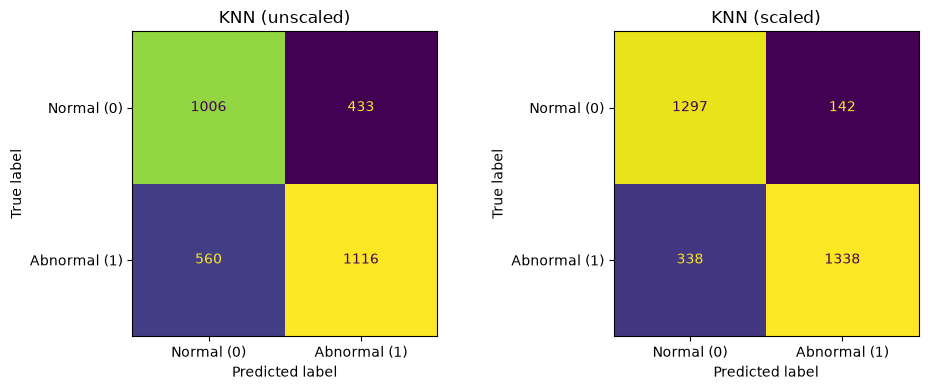

Saved: c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\knn_validation.csv


In [62]:
def validation_metrics(model, X_val, y_val):
    """Return the validation metrics of a trained model as a dictionary (positive class = 1, abnormal)."""
    y_pred = model.predict(X_val)
    y_score = model.predict_proba(X_val)[:, 1]
    metrics = {}
    metrics["accuracy"] = accuracy_score(y_val, y_pred)
    metrics["precision"] = precision_score(y_val, y_pred)
    metrics["recall"] = recall_score(y_val, y_pred)
    metrics["f1"] = f1_score(y_val, y_pred)
    metrics["roc_auc"] = roc_auc_score(y_val, y_score)
    metrics["balanced_accuracy"] = balanced_accuracy_score(y_val, y_pred)
    return metrics, y_pred


knn_rows = []
knn_predictions = {}
for use_scaling in [False, True]:
    if use_scaling:
        version = "KNN (scaled)"
        knn_pipeline = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())])
    else:
        version = "KNN (unscaled)"
        knn_pipeline = Pipeline([("model", KNeighborsClassifier())])

    knn_pipeline.fit(X_train_part, y_train_part)
    knn_metrics, knn_pred = validation_metrics(knn_pipeline, X_val_part, y_val_part)
    knn_metrics["model"] = version
    knn_rows.append(knn_metrics)
    knn_predictions[version] = knn_pred
    print(version, "-> validation F1 =", round(knn_metrics["f1"], 4))

knn_table = pd.DataFrame(knn_rows)
display(knn_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_index = 0
for version in knn_predictions:
    cm_display = ConfusionMatrixDisplay(confusion_matrix(y_val_part, knn_predictions[version]), display_labels=["Normal (0)", "Abnormal (1)"])
    cm_display.plot(ax=axes[plot_index], colorbar=False, values_format="d")
    axes[plot_index].set_title(version)
    plot_index = plot_index + 1
plt.tight_layout()
plt.show()

knn_table.to_csv(RESULTS_DIR / "knn_validation.csv", index=False)
print("Saved:", RESULTS_DIR / "knn_validation.csv")